# Лабораторная работа №1 — разведочный анализ данных

**Тема:** исследование характеристик компьютерных игр платформы Steam.

В работе выполняется разведочный анализ подготовленной Iceberg-таблицы средствами Apache Spark. Анализ включает проверку качества данных, обработку пропусков и дубликатов, описательную статистику, исследование распределений и выбросов, анализ многозначных категориальных признаков и корреляционный анализ.

> Исходная Iceberg-таблица не изменяется. Все операции очистки и формирования признаков выполняются в рабочем DataFrame этой лабораторной работы.

**Особенности датасета, которые важно учитывать при анализе:**
- почти все количественные признаки (`reviews_total`, `recommendations`, `peak_ccu`, время игры и др.) имеют сильную правостороннюю скошенность и «нулевую инфляцию» — большая доля игр имеет нулевые значения;
- из-за этого сырые гистограммы и IQR-анализ на исходных значениях неинформативны. Распределения скошенных признаков анализируются в `log1p`-масштабе только по положительным значениям, а доля нулей приводится отдельно;
- поле `tags` в датасете ограничено 20 значениями на игру, поэтому на гистограмме `tags_count` присутствует всплеск на 20;
- `metacritic_score = 0` в исходных данных означает отсутствие оценки и в EDA трактуется как пропуск;
- признак `price` содержит аномальное значение 107500 — это реальная цена редких изданий Steam, поэтому она не удаляется.

## 1. Инициализация

Подключаем библиотеки, создаём Spark-сессию и задаём пути для результатов анализа и графиков.

In [1]:
%matplotlib inline

import sys
import numpy as np
from pathlib import Path
from itertools import combinations

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from pyspark.sql.functions import (
    array_distinct,
    avg,
    col,
    count,
    desc,
    explode,
    floor,
    isnan,
    log1p,
    max as spark_max,
    min as spark_min,
    percentile_approx,
    size,
    sum as spark_sum,
    when,
    year,
)

from pyspark.sql.types import (
    ArrayType,
    NumericType,
    StringType,
)

# Корень проекта в sys.path (src/ лежит на уровень выше notebooks/)
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "src").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT))

from src.spark_session import create_spark, catalog_name

spark = create_spark("Lab_1_data_analysis")

# Имя таблицы по требованию преподавателя: каталог.фамилия_database.таблица
CATALOG = catalog_name()
DATABASE_NAME = "sidsky_nikita_database"
TABLE_NAME = f"{CATALOG}.{DATABASE_NAME}.steam_games"

RESULTS_DIR = PROJECT_ROOT / "output" / "results"
PLOTS_DIR = PROJECT_ROOT / "output" / "plots"

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid")

print("Каталог Iceberg:", CATALOG)
print("Таблица:", TABLE_NAME)
print("Результаты:", RESULTS_DIR)
print("Графики:", PLOTS_DIR)


Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/09/19 20:49:42 WARN Client: Neither spark.yarn.jars nor spark.yarn.archive is set, falling back to uploading libraries under SPARK_HOME.


Каталог Iceberg: spark_catalog
Таблица: spark_catalog.sidsky_nikita_database.steam_games
Результаты: /home/user7/sidsky_nikita_sapr11/big_data_light/output/results
Графики: /home/user7/sidsky_nikita_sapr11/big_data_light/output/plots


## 2. Загрузка данных

Для анализа используется подготовленная Iceberg-таблица, полученная в первой части лабораторной работы.

In [2]:
df = spark.table(TABLE_NAME)

total_rows = df.count()

print("Количество строк:", f"{total_rows:,}")
print("Количество столбцов:", len(df.columns))

df.printSchema()


Количество строк: 141,148
Количество столбцов: 24
root
 |-- app_id: long (nullable = true)
 |-- name: string (nullable = true)
 |-- release_date: date (nullable = true)
 |-- price: double (nullable = true)
 |-- genres: array (nullable = true)
 |    |-- element: string (containsNull = true)
 |-- categories: array (nullable = true)
 |    |-- element: string (containsNull = true)
 |-- tags: array (nullable = true)
 |    |-- element: string (containsNull = true)
 |-- positive: long (nullable = true)
 |-- negative: long (nullable = true)
 |-- recommendations: long (nullable = true)
 |-- peak_ccu: long (nullable = true)
 |-- metacritic_score: integer (nullable = true)
 |-- average_playtime_forever: long (nullable = true)
 |-- median_playtime_forever: long (nullable = true)
 |-- achievements: integer (nullable = true)
 |-- dlc_count: integer (nullable = true)
 |-- windows: boolean (nullable = true)
 |-- mac: boolean (nullable = true)
 |-- linux: boolean (nullable = true)
 |-- estimated_owners

In [3]:
df.orderBy("app_id").show(20, truncate=False)


+------+------------------------------+------------+-----+--------+--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+--------+--------+---------------+--------+----------------+------------------------+-----------------------+------------+-

## 3. Проверка целостности набора данных

Проверяем, что `app_id` уникален и не содержит пропусков.

In [4]:
null_app_id = df.filter(col("app_id").isNull()).count()

unique_app_id = df.select("app_id").distinct().count()

duplicate_app_ids = (
    df
    .filter(col("app_id").isNotNull())
    .groupBy("app_id")
    .count()
    .filter(col("count") > 1)
    .orderBy(desc("count"))
)

print("NULL app_id:", f"{null_app_id:,}")
print("Уникальных app_id:", f"{unique_app_id:,}")
print("app_id с повторениями:", f"{duplicate_app_ids.count():,}")

duplicate_app_ids.show(20, truncate=False)


NULL app_id: 0
Уникальных app_id: 141,148


app_id с повторениями: 0


+------+-----+
|app_id|count|
+------+-----+
+------+-----+



## 4. Пропущенные значения до очистки

Для каждого признака определяем количество и долю пропущенных значений. Для числовых признаков дополнительно учитывается `NaN`.

In [5]:
def build_missing_report(dataframe, total):
    """Сводка по пропускам для числовых и строковых столбцов."""
    float_columns = {
        name for name, dtype in dataframe.dtypes if dtype in {"float", "double"}
    }

    missing_expressions = []
    for column_name in dataframe.columns:
        missing_condition = col(column_name).isNull()
        if column_name in float_columns:
            missing_condition = missing_condition | isnan(col(column_name))
        missing_expressions.append(
            spark_sum(when(missing_condition, 1).otherwise(0)).alias(column_name)
        )

    missing_counts = dataframe.select(*missing_expressions).first().asDict()

    report = pd.DataFrame({
        "column": dataframe.columns,
        "missing_count": [missing_counts[c] for c in dataframe.columns],
    })
    report["missing_percent"] = report["missing_count"] / total * 100
    return report.sort_values("missing_percent", ascending=False).reset_index(drop=True)


missing_before = build_missing_report(df, total_rows)
display(missing_before)


,column,missing_count,missing_percent
0,metacritic_score,42213,29.906906
1,recommendations,34891,24.719443
2,achievements,18388,13.027461
3,supported_languages_count,8396,5.948366
4,price,1236,0.875677
5,release_date,82,0.058095
6,full_audio_languages_count,20,0.014170
7,name,15,0.010627
8,mac,14,0.009919
9,windows,14,0.009919


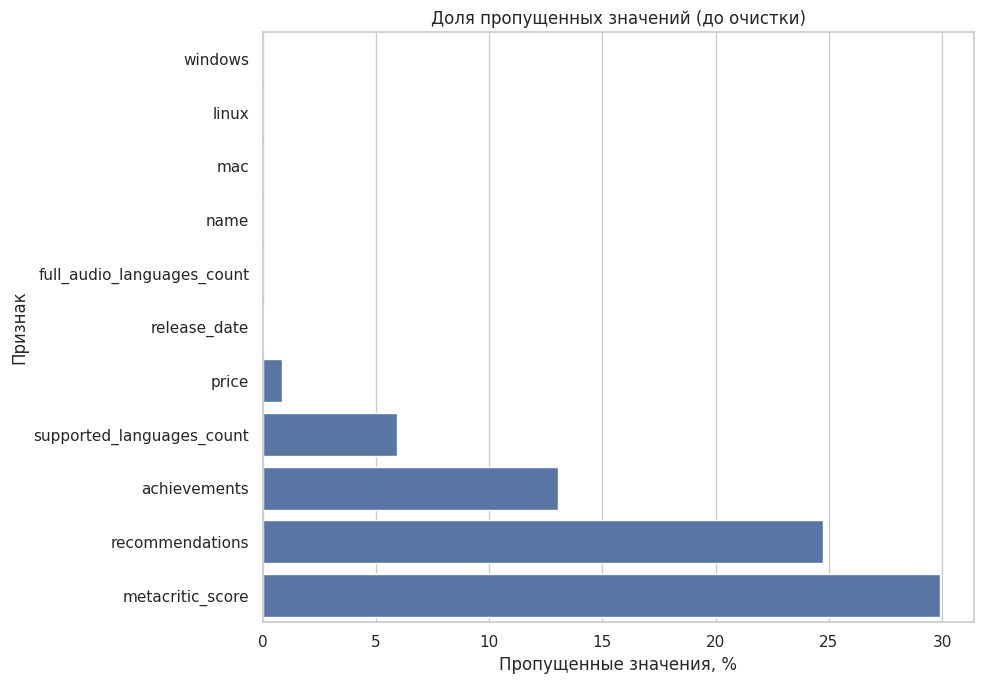

In [6]:
missing_before.to_csv(RESULTS_DIR / "missing_values_before.csv", index=False)

missing_plot = missing_before[missing_before["missing_count"] > 0].sort_values("missing_percent")

if not missing_plot.empty:
    plt.figure(figsize=(10, 7))
    sns.barplot(data=missing_plot, x="missing_percent", y="column")
    plt.xlabel("Пропущенные значения, %")
    plt.ylabel("Признак")
    plt.title("Доля пропущенных значений (до очистки)")
    plt.tight_layout()
    plt.savefig(PLOTS_DIR / "01_missing_values_before.png", dpi=150, bbox_inches="tight")
    plt.show()


## 5. Пустые строки и пустые массивы

`genres`, `categories` и `tags` — массивы. Для них отдельно учитываются `NULL` и пустые массивы. Это позволяет не путать отсутствие значения с корректным пустым списком.

In [7]:
string_columns = [
    field.name for field in df.schema.fields
    if isinstance(field.dataType, StringType)
]

empty_rows = []
for column_name in string_columns:
    empty_count = df.filter(
        col(column_name).isNotNull() & (col(column_name) == "")
    ).count()
    empty_rows.append({
        "column": column_name,
        "empty_count": empty_count,
        "empty_percent": empty_count / total_rows * 100,
    })

display(pd.DataFrame(empty_rows))


,column,empty_count,empty_percent
0,name,0,0.0


In [8]:
array_columns = [
    field.name for field in df.schema.fields
    if isinstance(field.dataType, ArrayType)
]

array_rows = []
for column_name in array_columns:
    stats = (
        df.select(
            spark_sum(when(col(column_name).isNull(), 1).otherwise(0)).alias("null_count"),
            spark_sum(
                when(col(column_name).isNotNull() & (size(col(column_name)) == 0), 1).otherwise(0)
            ).alias("empty_count"),
            spark_max(size(col(column_name))).alias("max_size"),
        ).first()
    )
    array_rows.append({
        "column": column_name,
        "null_count": stats["null_count"],
        "empty_count": stats["empty_count"],
        "max_size": stats["max_size"],
        "null_percent": stats["null_count"] / total_rows * 100,
        "empty_percent": stats["empty_count"] / total_rows * 100,
    })

display(pd.DataFrame(array_rows))


,column,null_count,empty_count,max_size,null_percent,empty_percent
0,genres,0,8431,19,0.0,5.973163
1,categories,0,8962,34,0.0,6.349364
2,tags,0,57688,21,0.0,40.870576


## 6. Нулевые значения

Нули не всегда являются пропусками: `price = 0` — бесплатная игра, `dlc_count = 0` — отсутствие DLC, `positive = 0` — отсутствие отзывов. Нули не удаляются, но их доля важна для интерпретации распределений.

In [9]:
numeric_columns = [
    field.name for field in df.schema.fields
    if isinstance(field.dataType, NumericType)
]

zero_expressions = [
    spark_sum(when(col(c) == 0, 1).otherwise(0)).alias(c)
    for c in numeric_columns
]
zero_counts = df.select(*zero_expressions).first().asDict()

zero_report = pd.DataFrame({
    "column": numeric_columns,
    "zero_count": [zero_counts[c] for c in numeric_columns],
})
zero_report["zero_percent"] = zero_report["zero_count"] / total_rows * 100
zero_report = zero_report.sort_values("zero_percent", ascending=False).reset_index(drop=True)

display(zero_report)
zero_report.to_csv(RESULTS_DIR / "zero_values.csv", index=False)


,column,zero_count,zero_percent
0,average_playtime_forever,129775,91.942500
1,median_playtime_forever,129775,91.942500
2,peak_ccu,121432,86.031683
3,dlc_count,120780,85.569757
4,estimated_owners_min,115523,81.845297
5,metacritic_score,94645,67.053731
6,full_audio_languages_count,88579,62.756114
7,recommendations,84040,59.540341
8,negative,73618,52.156602
9,positive,60692,42.998838


## 7. Проверка корректности значений

Проверяем значения, которые физически или логически не должны встречаться в наборе (отрицательные цены, отрицательные отзывы, выход `metacritic_score` за диапазон и т.д.).

In [10]:
validation_rules = [
    ("invalid_app_id", "app_id <= 0", col("app_id") <= 0),
    ("negative_price", "price < 0", col("price") < 0),
    ("negative_owners_min", "estimated_owners_min < 0", col("estimated_owners_min") < 0),
    ("negative_owners_max", "estimated_owners_max < 0", col("estimated_owners_max") < 0),
    (
        "owners_min_gt_max",
        "estimated_owners_min > estimated_owners_max",
        col("estimated_owners_min") > col("estimated_owners_max"),
    ),
    ("negative_positive", "positive < 0", col("positive") < 0),
    ("negative_negative", "negative < 0", col("negative") < 0),
    ("negative_recommendations", "recommendations < 0", col("recommendations") < 0),
    ("negative_peak_ccu", "peak_ccu < 0", col("peak_ccu") < 0),
    (
        "invalid_metacritic",
        "metacritic_score < 0 or > 100",
        (col("metacritic_score") < 0) | (col("metacritic_score") > 100),
    ),
    ("negative_avg_playtime", "average_playtime_forever < 0", col("average_playtime_forever") < 0),
    ("negative_median_playtime", "median_playtime_forever < 0", col("median_playtime_forever") < 0),
    ("negative_achievements", "achievements < 0", col("achievements") < 0),
    ("negative_dlc_count", "dlc_count < 0", col("dlc_count") < 0),
    (
        "negative_supported_languages",
        "supported_languages_count < 0",
        col("supported_languages_count") < 0,
    ),
    (
        "negative_audio_languages",
        "full_audio_languages_count < 0",
        col("full_audio_languages_count") < 0,
    ),
    (
        "audio_gt_supported",
        "full_audio_languages_count > supported_languages_count",
        col("full_audio_languages_count") > col("supported_languages_count"),
    ),
]

validation_counts = (
    df.select(
        *[
            spark_sum(when(condition, 1).otherwise(0)).alias(rule_name)
            for rule_name, _, condition in validation_rules
        ]
    ).first().asDict()
)

validation_report = pd.DataFrame([
    {"rule": r, "condition": d, "count": validation_counts[r]}
    for r, d, _ in validation_rules
])
validation_report.to_csv(RESULTS_DIR / "validation_rules.csv", index=False)

display(validation_report)


,rule,condition,count
0,invalid_app_id,app_id <= 0,0
1,negative_price,price < 0,0
2,negative_owners_min,estimated_owners_min < 0,0
3,negative_owners_max,estimated_owners_max < 0,0
4,owners_min_gt_max,estimated_owners_min > estimated_owners_max,0
5,negative_positive,positive < 0,0
6,negative_negative,negative < 0,0
7,negative_recommendations,recommendations < 0,0
8,negative_peak_ccu,peak_ccu < 0,0
9,invalid_metacritic,metacritic_score < 0 or > 100,0


## 8. Удаление дубликатов внутри массивов

Одинаковые категории у разных игр — нормальные данные. Но если одна и та же категория встречается несколько раз внутри списка одной игры, это дублирование одного значения. Для устранения создаём рабочий DataFrame `df_clean`.

In [11]:
df_clean = (
    df
    .withColumn("genres", array_distinct(col("genres")))
    .withColumn("categories", array_distinct(col("categories")))
    .withColumn("tags", array_distinct(col("tags")))
)

dup_rows = []
for column_name in ["genres", "categories", "tags"]:
    duplicate_count = df.filter(
        size(array_distinct(col(column_name))) < size(col(column_name))
    ).count()
    dup_rows.append({
        "column": column_name,
        "rows_with_duplicates_before": duplicate_count,
        "percent": duplicate_count / total_rows * 100,
    })

display(pd.DataFrame(dup_rows))

dup_after_rows = []
for column_name in ["genres", "categories", "tags"]:
    duplicate_count = df_clean.filter(
        size(array_distinct(col(column_name))) < size(col(column_name))
    ).count()
    dup_after_rows.append({
        "column": column_name,
        "rows_with_duplicates_after": duplicate_count,
    })

display(pd.DataFrame(dup_after_rows))


,column,rows_with_duplicates_before,percent
0,genres,0,0.000000
1,categories,1659,1.175362
2,tags,0,0.000000


,column,rows_with_duplicates_after
0,genres,0
1,categories,0
2,tags,0


## 9. Обработка пропусков и формирование аналитических признаков

Применяем только содержательно обоснованные преобразования:

- `metacritic_score = 0` трактуется как отсутствие оценки и заменяется на `NULL`;
- нули в `price`, `dlc_count`, времени игры сохраняются как реальные значения;
- пустые массивы `genres`, `categories`, `tags` сохраняются;
- создаются признаки `reviews_total`, `positive_ratio`, `is_free`, `release_year` и счётчики количества элементов в массивах.

In [12]:
df_clean = (
    df_clean
    .withColumn(
        "metacritic_score",
        when(col("metacritic_score") == 0, None).otherwise(col("metacritic_score")),
    )
    .withColumn(
        "reviews_total",
        col("positive") + col("negative"),
    )
    .withColumn(
        "positive_ratio",
        when(
            col("positive") + col("negative") > 0,
            col("positive") / (col("positive") + col("negative")),
        ),
    )
    .withColumn("release_year", year(col("release_date")))
    .withColumn(
        "is_free",
        when(col("price").isNull(), None).otherwise(col("price") == 0),
    )
    .withColumn("genres_count", size(col("genres")))
    .withColumn("categories_count", size(col("categories")))
    .withColumn("tags_count", size(col("tags")))
    .withColumn(
        "platform_count",
        when(
            col("windows").isNull() | col("mac").isNull() | col("linux").isNull(),
            None,
        ).otherwise(
            col("windows").cast("integer")
            + col("mac").cast("integer")
            + col("linux").cast("integer")
        ),
    )
)

print("Строк:", f"{df_clean.count():,}")
print("Metacritic = 0 (должно быть 0):", df_clean.filter(col("metacritic_score") == 0).count())
print("Metacritic не NULL:", df_clean.filter(col("metacritic_score").isNotNull()).count())


Строк: 141,148
Metacritic = 0 (должно быть 0): 0
Metacritic не NULL: 4290


## 10. Пропуски после очистки

После того как `metacritic_score = 0` был переведён в `NULL`, набор пропусков изменился. Ниже — актуальная картина.

26/09/19 20:58:58 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


,column,missing_count,missing_percent
0,metacritic_score,136858,96.960637
1,positive_ratio,58081,41.149007
2,recommendations,34891,24.719443
3,achievements,18388,13.027461
4,supported_languages_count,8396,5.948366
5,is_free,1236,0.875677
6,price,1236,0.875677
7,release_date,82,0.058095
8,release_year,82,0.058095
9,full_audio_languages_count,20,0.014170


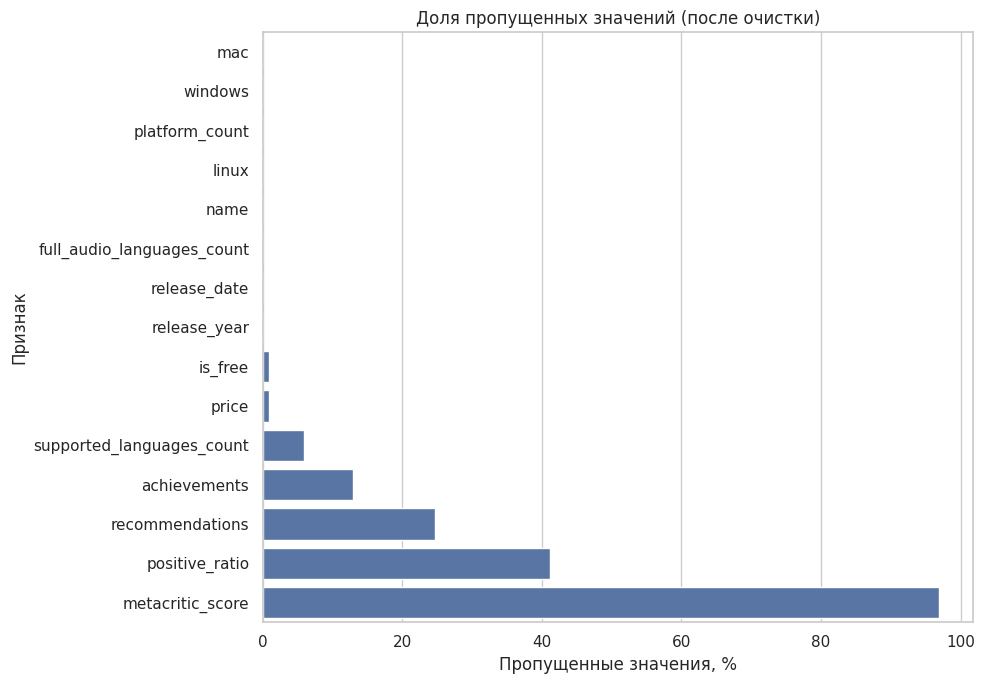

In [13]:
missing_after = build_missing_report(df_clean, total_rows)
missing_after.to_csv(RESULTS_DIR / "missing_values_after.csv", index=False)

display(missing_after)

missing_plot = missing_after[missing_after["missing_count"] > 0].sort_values("missing_percent")
if not missing_plot.empty:
    plt.figure(figsize=(10, 7))
    sns.barplot(data=missing_plot, x="missing_percent", y="column")
    plt.xlabel("Пропущенные значения, %")
    plt.ylabel("Признак")
    plt.title("Доля пропущенных значений (после очистки)")
    plt.tight_layout()
    plt.savefig(PLOTS_DIR / "02_missing_values_after.png", dpi=150, bbox_inches="tight")
    plt.show()


## 11. Описательная статистика числовых признаков

Для признаков с выраженной асимметрией медиана и квартили информативнее среднего, поэтому смотрим оба типа характеристик. Дополнительно выводим долю нулей, чтобы сразу видеть степень «нулевой инфляции».

In [14]:
analysis_numeric_columns = [
    "price",
    "estimated_owners_avg",
    "positive",
    "negative",
    "reviews_total",
    "positive_ratio",
    "recommendations",
    "peak_ccu",
    "metacritic_score",
    "average_playtime_forever",
    "median_playtime_forever",
    "achievements",
    "dlc_count",
    "supported_languages_count",
    "full_audio_languages_count",
    "genres_count",
    "categories_count",
    "tags_count",
    "platform_count",
]

df_clean.select(*analysis_numeric_columns).summary(
    "count", "min", "25%", "50%", "mean", "75%", "max"
).show(truncate=False)


+-------+-----------------+--------------------+-----------------+------------------+------------------+------------------+---------------+-----------------+----------------+------------------------+-----------------------+------------------+------------------+-------------------------+--------------------------+-----------------+-----------------+-----------------+-----------------+
|summary|price            |estimated_owners_avg|positive         |negative          |reviews_total     |positive_ratio    |recommendations|peak_ccu         |metacritic_score|average_playtime_forever|median_playtime_forever|achievements      |dlc_count         |supported_languages_count|full_audio_languages_count|genres_count     |categories_count |tags_count       |platform_count   |
+-------+-----------------+--------------------+-----------------+------------------+------------------+------------------+---------------+-----------------+----------------+------------------------+-----------------------+---

## 12. Распределения числовых признаков

Для признаков с сильной правосторонней скошенностью и «нулевой инфляцией» (`price`, `estimated_owners_avg`, `reviews_total`, `recommendations`, `peak_ccu`, время игры) сырые гистограммы неинформативны: все наблюдения сжимаются в один нулевой столбик. Поэтому:

- распределение строится по положительным значениям в `log1p`-масштабе;
- доля нулей выводится отдельной подписью на графике;
- для признаков с ограниченным диапазоном (`achievements`, `dlc_count`, счётчики массивов и языков) оставляем обычные гистограммы.

In [15]:
def plot_log_distribution(dataframe, column_name, plots_dir, sample_frac=0.2, seed=42):
    """Логарифмированное распределение положительных значений + доля нулей."""
    pdf = dataframe.select(column_name).sample(False, sample_frac, seed=seed).toPandas()
    series = pdf[column_name].dropna()
    if series.empty:
        return

    zero_share = (series == 0).mean()
    positive = series[series > 0]

    plt.figure(figsize=(9, 5))
    if not positive.empty:
        sns.histplot(np.log1p(positive), bins=50)
        plt.xlabel(f"log1p({column_name}), значения > 0")
    else:
        plt.text(0.5, 0.5, "Нет положительных значений", ha="center")

    plt.ylabel("Количество игр")
    plt.title(f"Распределение {column_name} (только > 0). Доля нулей: {zero_share:.1%}")
    plt.tight_layout()
    plt.savefig(plots_dir / f"03_log_distribution_{column_name}.png", dpi=150, bbox_inches="tight")
    plt.show()


def plot_raw_distribution(dataframe, column_name, plots_dir, sample_frac=0.2, seed=42):
    """Обычная гистограмма для признаков с ограниченным диапазоном."""
    pdf = dataframe.select(column_name).sample(False, sample_frac, seed=seed).toPandas()
    series = pdf[column_name].dropna()
    if series.empty:
        return

    plt.figure(figsize=(9, 5))
    sns.histplot(series, bins=40)
    plt.xlabel(column_name)
    plt.ylabel("Количество игр")
    plt.title(f"Распределение {column_name}")
    plt.tight_layout()
    plt.savefig(plots_dir / f"04_raw_distribution_{column_name}.png", dpi=150, bbox_inches="tight")
    plt.show()


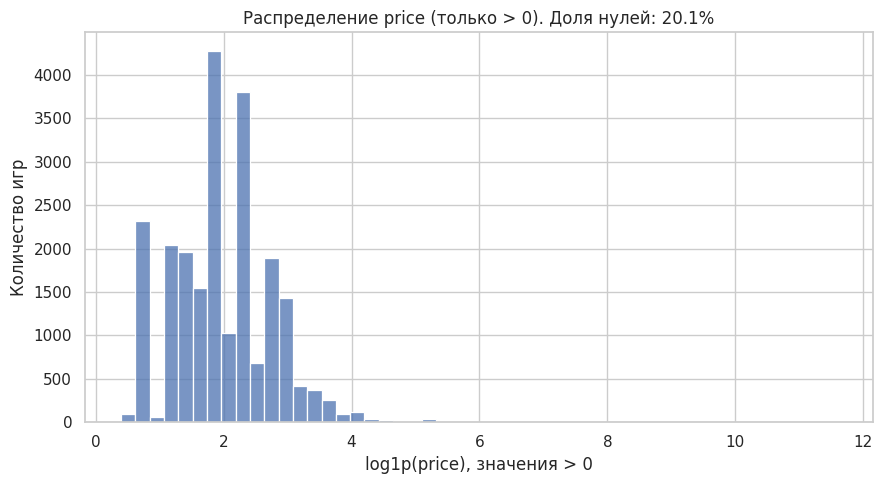

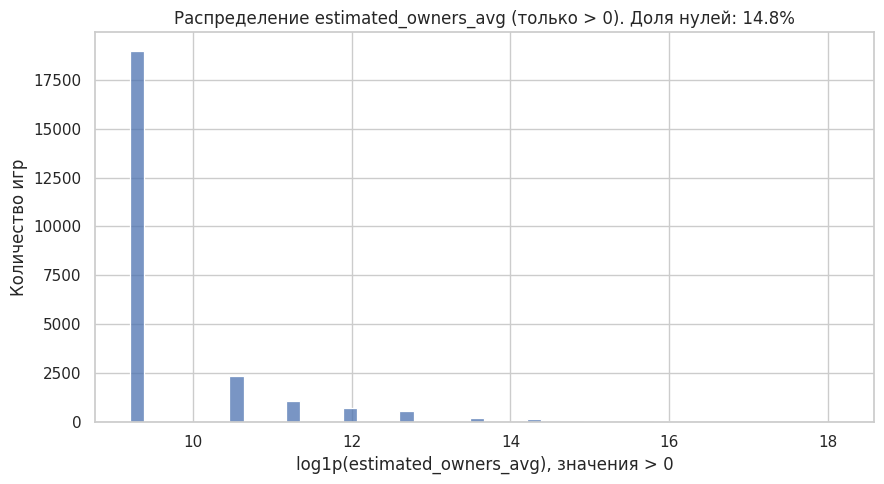

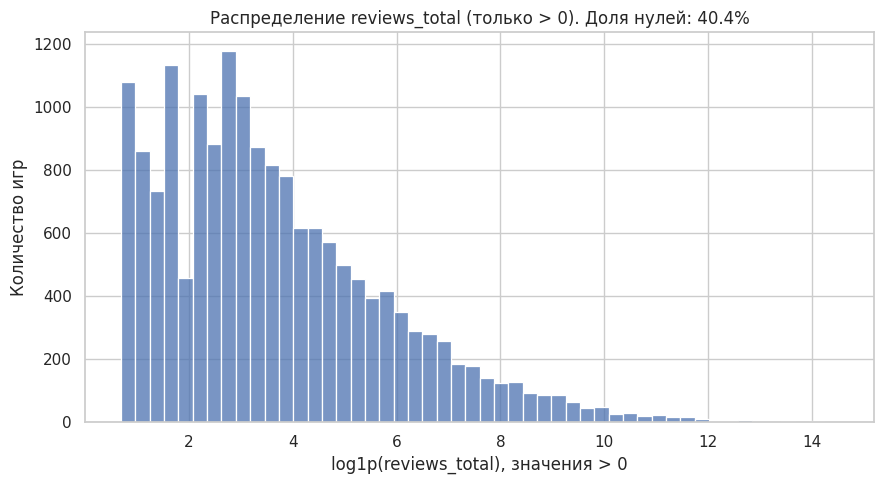

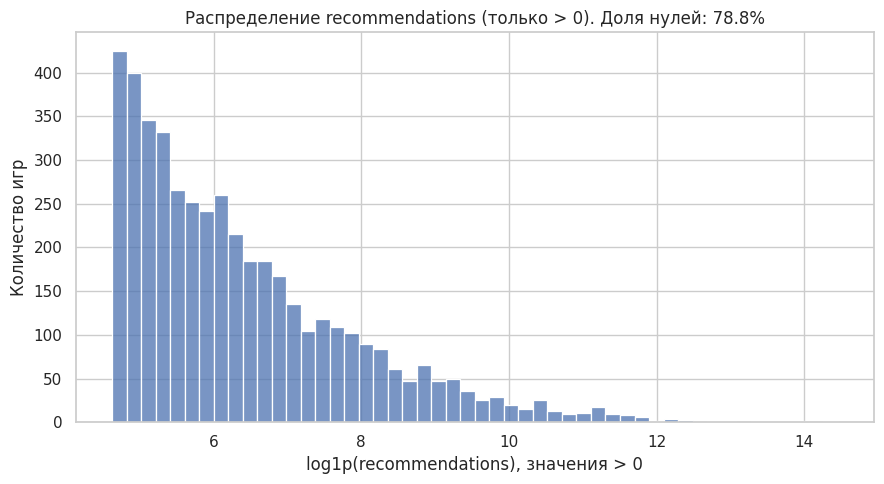

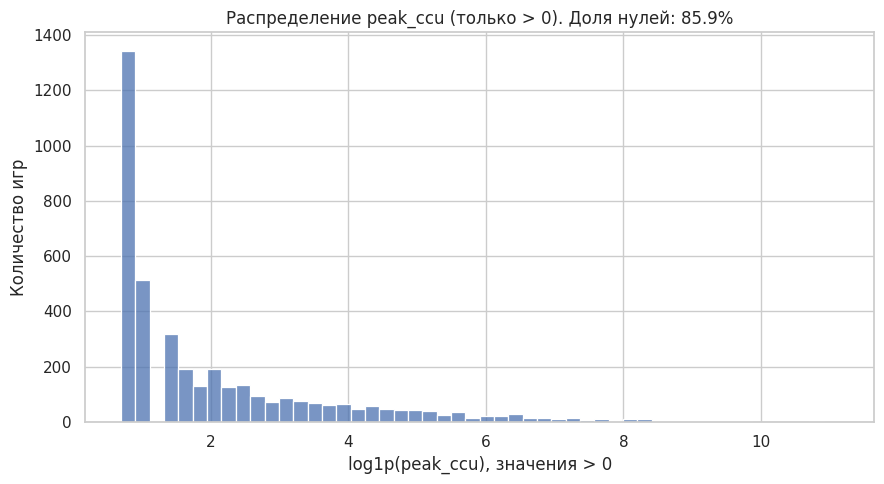

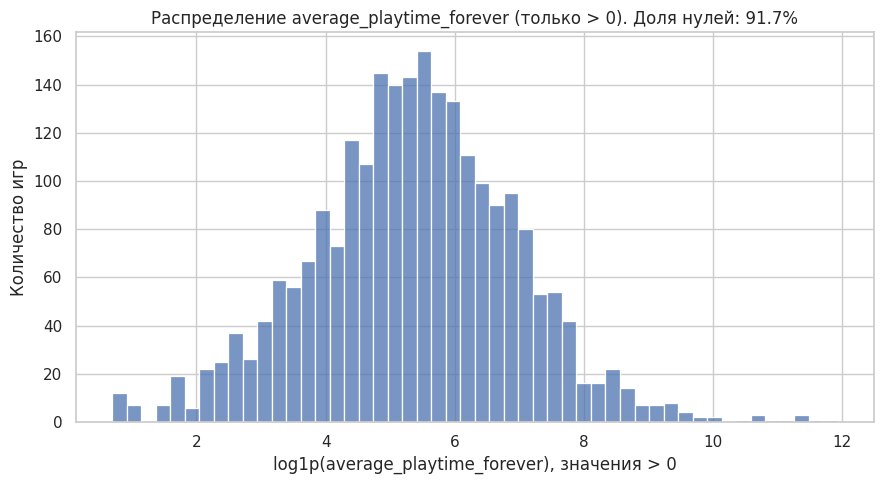

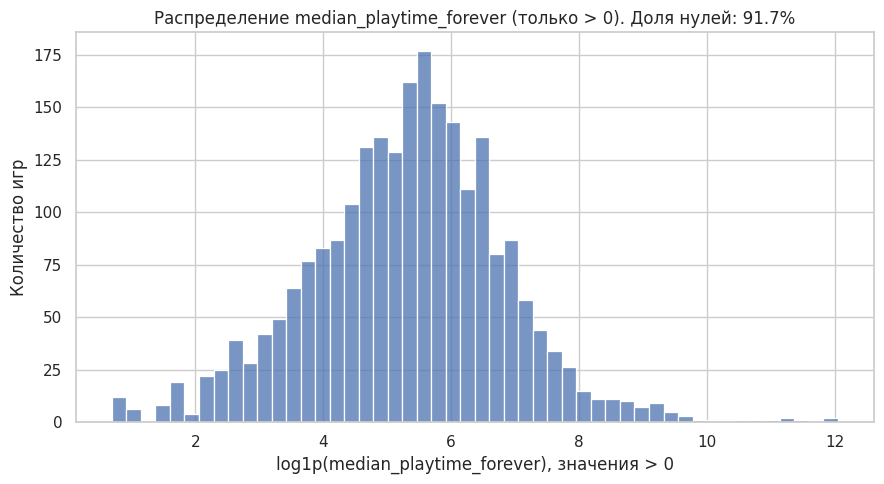

In [16]:
skewed_columns = [
    "price",
    "estimated_owners_avg",
    "reviews_total",
    "recommendations",
    "peak_ccu",
    "average_playtime_forever",
    "median_playtime_forever",
]

for column_name in skewed_columns:
    plot_log_distribution(df_clean, column_name, PLOTS_DIR)


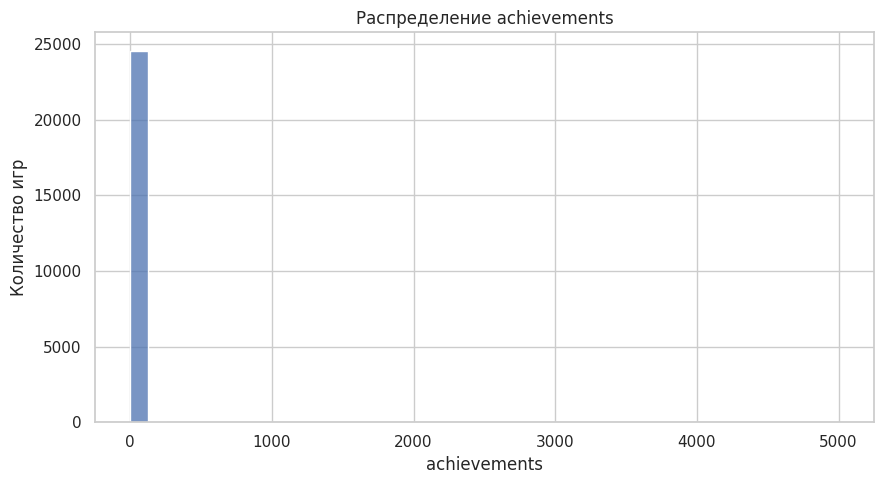

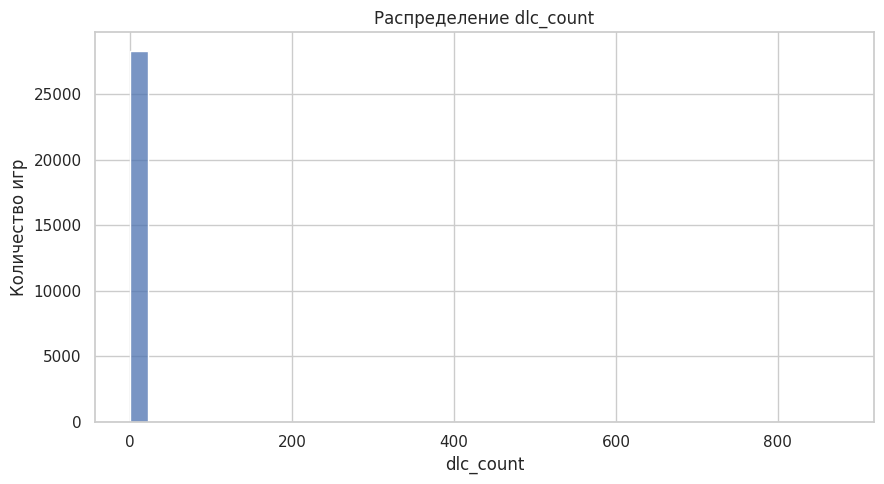

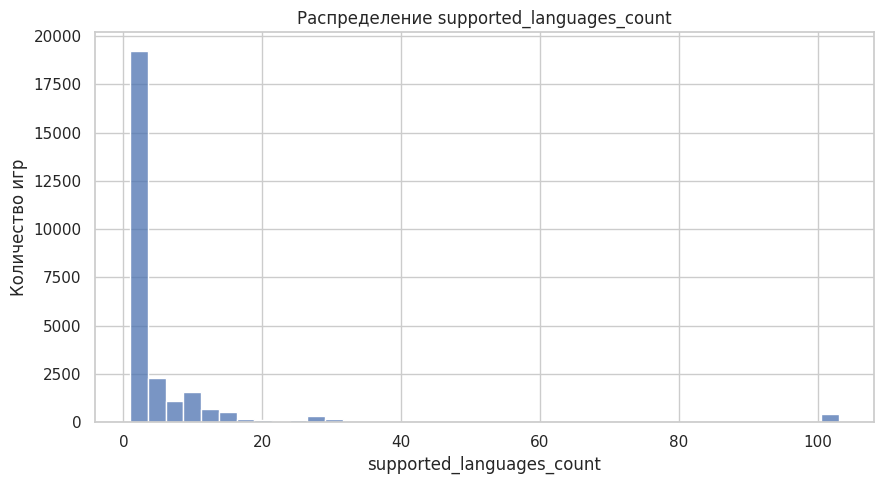

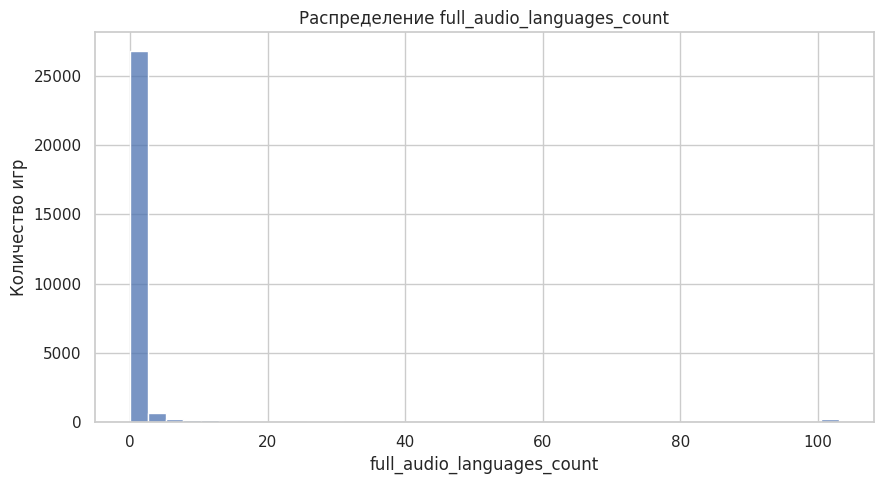

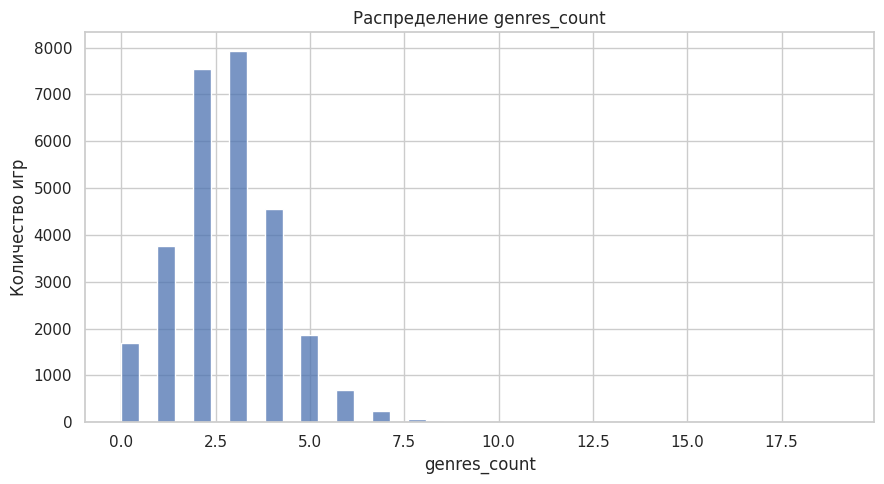

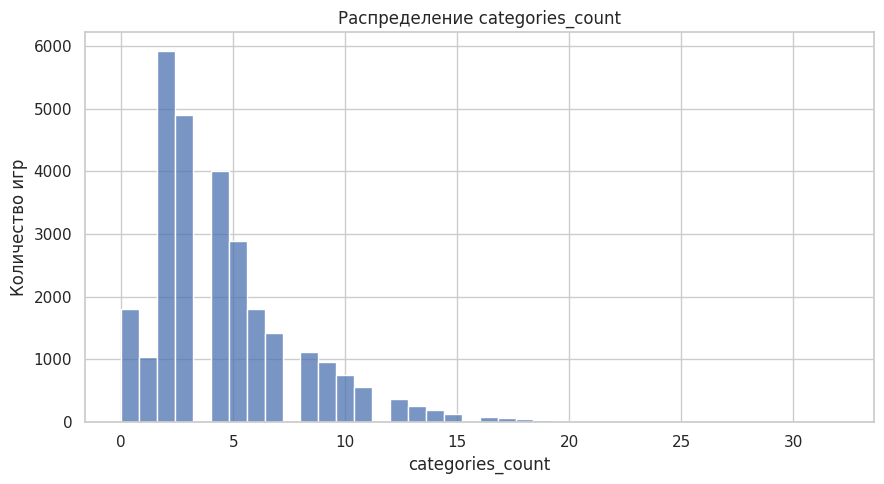

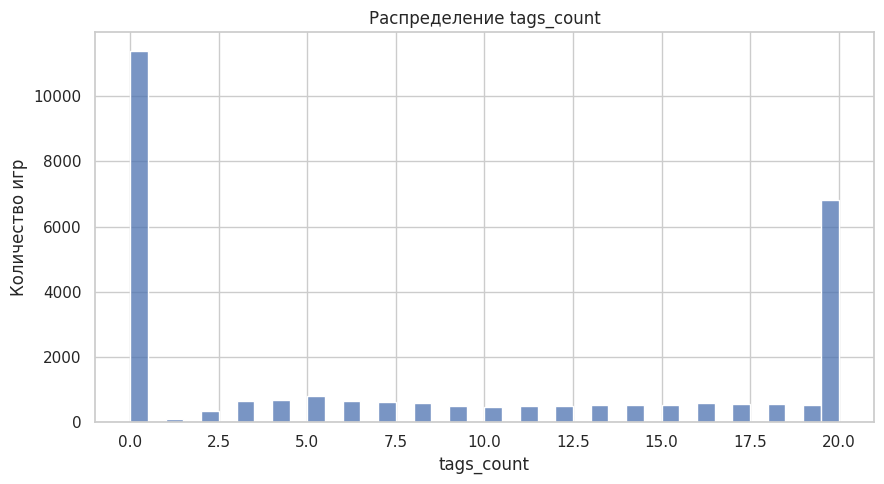

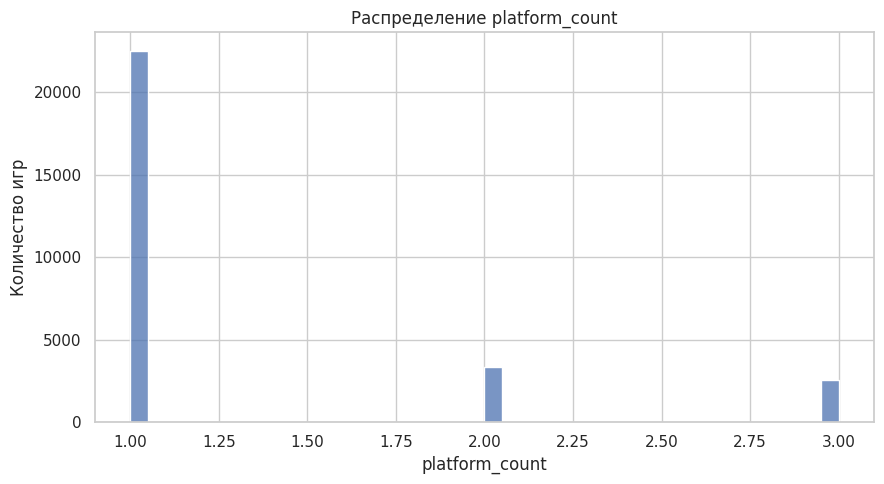

In [17]:
bounded_columns = [
    "achievements",
    "dlc_count",
    "supported_languages_count",
    "full_audio_languages_count",
    "genres_count",
    "categories_count",
    "tags_count",
    "platform_count",
]

for column_name in bounded_columns:
    plot_raw_distribution(df_clean, column_name, PLOTS_DIR)


## 13. Анализ цены

Цена имеет особый смысл: `0` соответствует бесплатной игре. Отдельно рассматриваются доля бесплатных игр и распределение цен среди платных. Аномальное значение `price = 107500` реально встречается в Steam и не удаляется.

In [18]:
price_stats = (
    df_clean.select(
        spark_sum(when(col("price") == 0, 1).otherwise(0)).alias("free_games"),
        spark_sum(when(col("price") > 0, 1).otherwise(0)).alias("paid_games"),
        spark_sum(when(col("price").isNull(), 1).otherwise(0)).alias("unknown_price"),
    ).first()
)

price_report = pd.DataFrame({
    "category": ["Бесплатные", "Платные", "Цена неизвестна"],
    "count": [price_stats["free_games"], price_stats["paid_games"], price_stats["unknown_price"]],
})
price_report["percent"] = price_report["count"] / total_rows * 100
display(price_report)


,category,count,percent
0,Бесплатные,27904,19.769320
1,Платные,112008,79.355003
2,Цена неизвестна,1236,0.875677


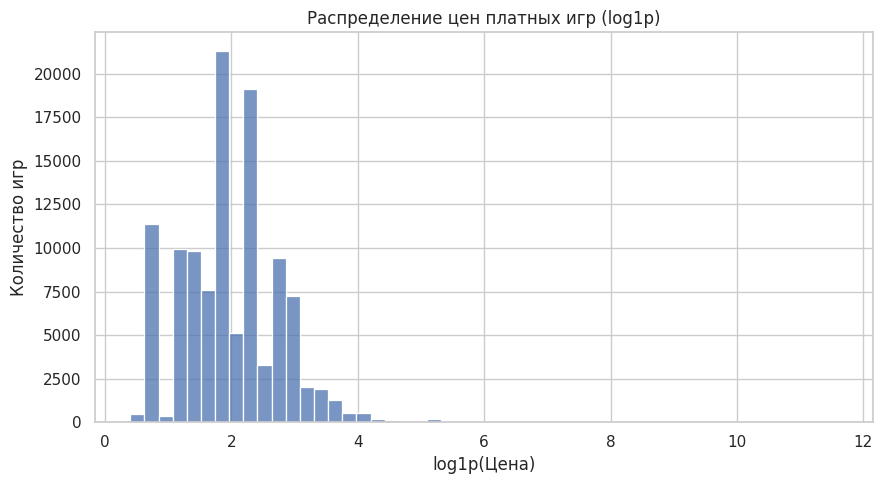

Максимум цены: 107500.0
Медиана цены платных игр: 5.99


In [19]:
paid_price_pdf = (
    df_clean
    .filter(col("price") > 0)
    .select("price")
    .toPandas()
)

plt.figure(figsize=(9, 5))
sns.histplot(np.log1p(paid_price_pdf["price"]), bins=50)
plt.xlabel("log1p(Цена)")
plt.ylabel("Количество игр")
plt.title("Распределение цен платных игр (log1p)")
plt.tight_layout()
plt.savefig(PLOTS_DIR / "05_paid_price_log_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

print("Максимум цены:", paid_price_pdf["price"].max())
print("Медиана цены платных игр:", paid_price_pdf["price"].median())


## 14. Поиск выбросов методом IQR

Из-за нулевой инфляции и сильной скошенности классический IQR на сырых значениях даёт `IQR = 0`, и любой ненулевой объект объявляется выбросом. Поэтому IQR считается **по положительным значениям в `log1p`-масштабе**. Доля нулей выводится отдельным столбцом.

Выход за границы IQR рассматривается как статистический выброс, но **не означает ошибку данных**: для Steam естественны игры с очень большой аудиторией, количеством отзывов или временем игры. Реальные экстремальные значения сохраняются.

In [20]:
outlier_columns = [
    "price",
    "estimated_owners_avg",
    "reviews_total",
    "recommendations",
    "peak_ccu",
    "average_playtime_forever",
    "median_playtime_forever",
    "achievements",
    "dlc_count",
    "supported_languages_count",
    "full_audio_languages_count",
]

outlier_rows = []
for column_name in outlier_columns:
    series = df_clean.select(column_name).toPandas()[column_name].dropna()
    if series.empty:
        continue

    zero_share = (series == 0).mean() * 100
    positive = series[series > 0]
    if positive.empty:
        continue

    log_pos = np.log1p(positive)
    q1, q3 = np.percentile(log_pos, [25, 75])
    median = np.median(log_pos)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    outlier_count = int(((log_pos < lower) | (log_pos > upper)).sum())

    outlier_rows.append({
        "column": column_name,
        "zero_percent": zero_share,
        "q1_log": q1,
        "median_log": median,
        "q3_log": q3,
        "iqr_log": iqr,
        "lower_log": lower,
        "upper_log": upper,
        "outlier_count_positive": outlier_count,
        "outlier_percent_positive": outlier_count / len(positive) * 100,
    })

outlier_report = pd.DataFrame(outlier_rows)
outlier_report.to_csv(RESULTS_DIR / "outliers_iqr_log.csv", index=False)
display(outlier_report.round(3))


,column,zero_percent,q1_log,median_log,q3_log,iqr_log,lower_log,upper_log,outlier_count_positive,outlier_percent_positive
0,price,19.944,1.384,1.944,2.397,1.013,-0.136,3.917,1478,1.320
1,estimated_owners_avg,14.997,9.210,9.210,9.210,0.000,9.210,9.210,25625,21.358
2,reviews_total,41.149,1.946,3.219,4.828,2.882,-2.378,9.152,1767,2.127
3,recommendations,79.091,5.215,6.004,7.226,2.011,2.198,10.243,667,3.002
4,peak_ccu,86.032,0.693,1.386,2.773,2.079,-2.426,5.892,941,4.773
5,average_playtime_forever,91.943,4.419,5.412,6.354,1.936,1.516,9.258,270,2.374
6,median_playtime_forever,91.943,4.419,5.407,6.254,1.835,1.666,9.006,303,2.664
7,achievements,39.668,2.398,2.944,3.497,1.099,0.750,5.144,2141,2.891
8,dlc_count,85.570,0.693,0.693,1.099,0.405,0.085,1.707,1981,9.726
9,supported_languages_count,0.000,0.693,0.693,1.609,0.916,-0.681,2.984,5619,4.233


### Boxplot скошенных признаков (log1p, только > 0)

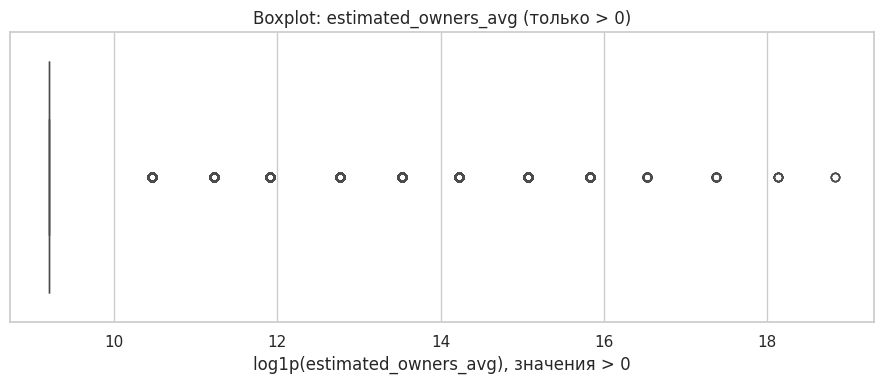

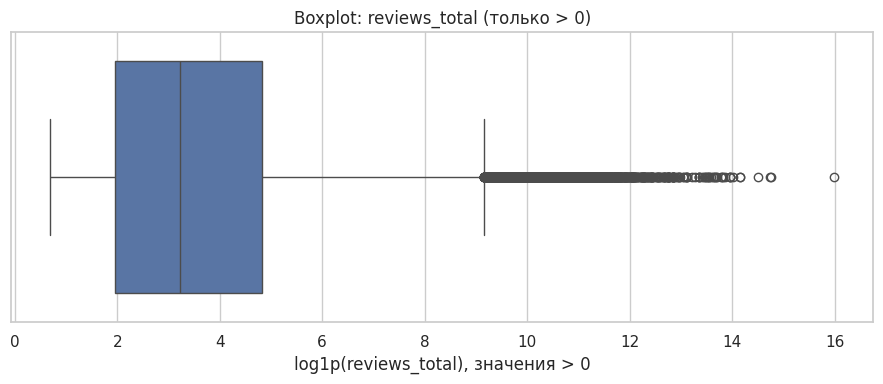

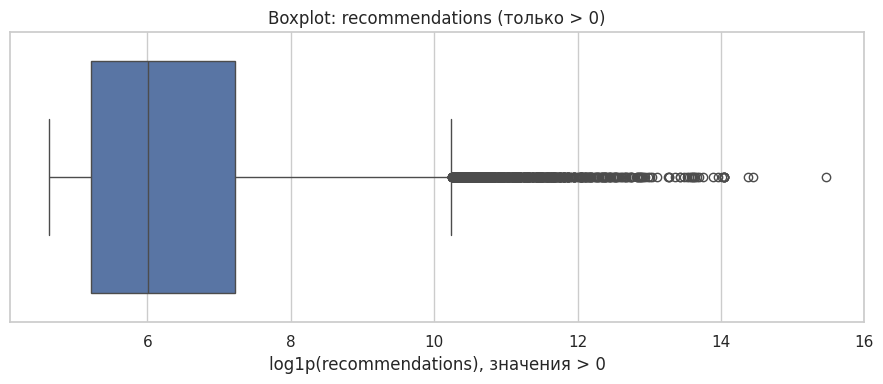

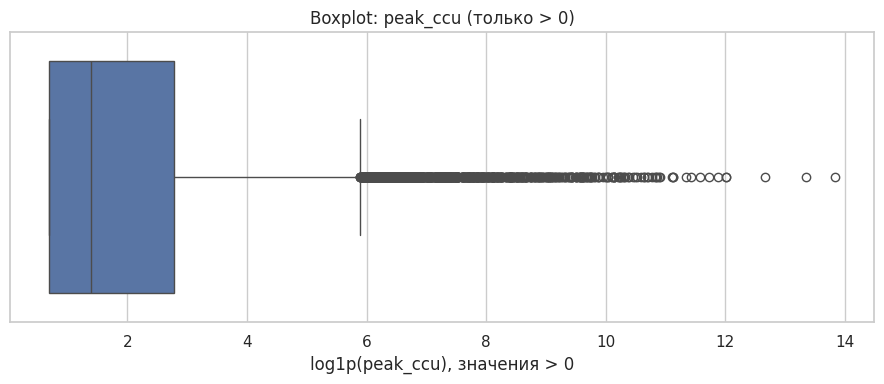

In [21]:
boxplot_columns = [
    "estimated_owners_avg",
    "reviews_total",
    "recommendations",
    "peak_ccu",
]

for column_name in boxplot_columns:
    series = df_clean.select(column_name).toPandas()[column_name].dropna()
    positive = series[series > 0]
    if positive.empty:
        continue

    plt.figure(figsize=(9, 4))
    sns.boxplot(x=np.log1p(positive))
    plt.xlabel(f"log1p({column_name}), значения > 0")
    plt.title(f"Boxplot: {column_name} (только > 0)")
    plt.tight_layout()
    plt.savefig(PLOTS_DIR / f"06_boxplot_{column_name}_log.png", dpi=150, bbox_inches="tight")
    plt.show()


## 15. Анализ годов выпуска

Исследуем распределение игр по году выпуска. В датасете присутствуют игры с датой релиза в будущем — это могут быть предзаказы, ранний доступ или ошибки разметки. Они не удаляются, но отмечаются на графике.

,release_year,count
10,2007,90
11,2008,158
12,2009,321
13,2010,255
14,2011,258
15,2012,322
16,2013,467
17,2014,1521
18,2015,2513
19,2016,4137


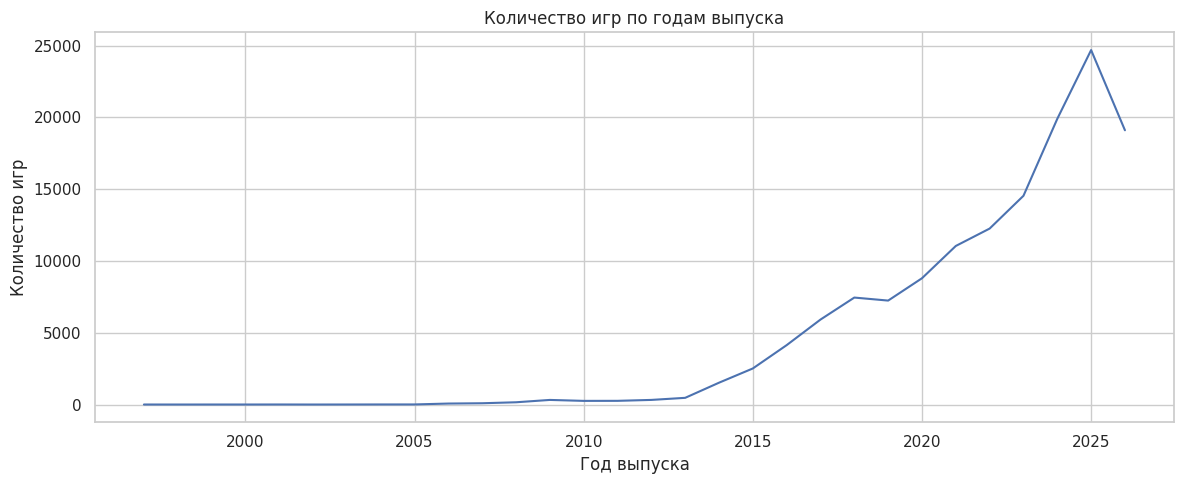

In [22]:
release_year_df = (
    df_clean
    .filter(col("release_year").isNotNull())
    .groupBy("release_year")
    .count()
    .orderBy("release_year")
)

release_year_pdf = release_year_df.toPandas()

display(release_year_pdf.tail(20))

plt.figure(figsize=(12, 5))
sns.lineplot(data=release_year_pdf, x="release_year", y="count")
plt.xlabel("Год выпуска")
plt.ylabel("Количество игр")
plt.title("Количество игр по годам выпуска")
plt.tight_layout()
plt.savefig(PLOTS_DIR / "07_games_by_release_year.png", dpi=150, bbox_inches="tight")
plt.show()


## 16. Анализ жанров, категорий и тегов

Многозначные признаки преобразуются в строки с помощью `explode`. Для каждого значения определяется количество игр, в которых оно встречается.

In [23]:
genres_df = (
    df_clean.select(explode("genres").alias("genre"))
    .filter(col("genre").isNotNull())
    .groupBy("genre").count().orderBy(desc("count"))
)

categories_df = (
    df_clean.select(explode("categories").alias("category"))
    .filter(col("category").isNotNull())
    .groupBy("category").count().orderBy(desc("count"))
)

tags_df = (
    df_clean.select(explode("tags").alias("tag"))
    .filter(col("tag").isNotNull())
    .groupBy("tag").count().orderBy(desc("count"))
)

print("ТОП-20 жанров")
genres_df.show(20, truncate=False)
print("ТОП-20 категорий")
categories_df.show(20, truncate=False)
print("ТОП-20 тегов")
tags_df.show(20, truncate=False)


ТОП-20 жанров


+---------------------+-----+
|genre                |count|
+---------------------+-----+
|Indie                |93985|
|Casual               |59215|
|Action               |52564|
|Adventure            |51184|
|Simulation           |28901|
|Strategy             |26773|
|RPG                  |24288|
|Free To Play         |14494|
|Early Access         |13205|
|Sports               |5516 |
|Racing               |4561 |
|Massively Multiplayer|2882 |
|Utilities            |1094 |
|Design & Illustration|583  |
|Animation & Modeling |480  |
|Education            |466  |
|Violent              |406  |
|Video Production     |340  |
|Game Development     |322  |
|Gore                 |255  |
+---------------------+-----+
only showing top 20 rows

ТОП-20 категорий


+----------------------------+------+
|category                    |count |
+----------------------------+------+
|Single-player               |125680|
|Family Sharing              |115741|
|Steam Achievements          |65925 |
|Steam Cloud                 |37138 |
|Full controller support     |29631 |
|Multi-player                |23611 |
|Partial Controller Support  |15038 |
|Playable without Timed Input|14727 |
|PvP                         |14559 |
|Custom Volume Controls      |14161 |
|Co-op                       |13016 |
|Steam Trading Cards         |11596 |
|Steam Leaderboards          |10613 |
|Online PvP                  |10421 |
|Remote Play Together        |8535  |
|Shared/Split Screen         |8359  |
|Online Co-op                |8339  |
|Save Anytime                |8059  |
|Stereo Sound                |7945  |
|Mouse Only Option           |6937  |
+----------------------------+------+
only showing top 20 rows

ТОП-20 тегов


+--------------+-----+
|tag           |count|
+--------------+-----+
|Singleplayer  |50389|
|Indie         |48603|
|Action        |36858|
|Casual        |36618|
|Adventure     |35241|
|2D            |26813|
|3D            |18002|
|Simulation    |17914|
|Strategy      |17871|
|Puzzle        |16392|
|Atmospheric   |16296|
|RPG           |15767|
|Colorful      |14267|
|Pixel Graphics|13877|
|Story Rich    |13363|
|Exploration   |13247|
|Cute          |12684|
|First-Person  |12303|
|Fantasy       |11513|
|Arcade        |11505|
+--------------+-----+
only showing top 20 rows



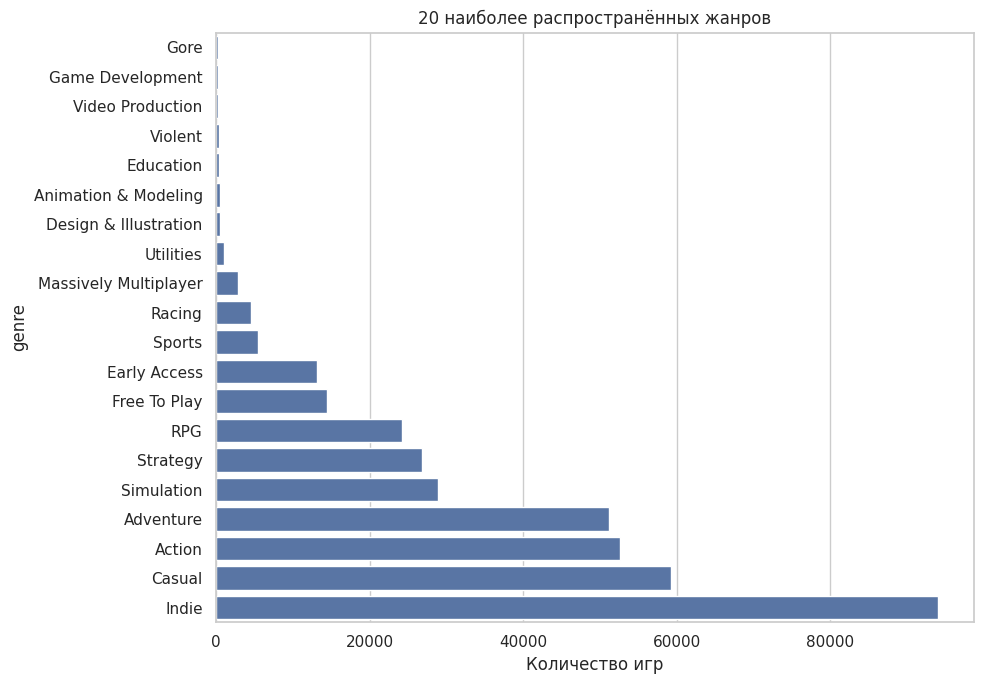

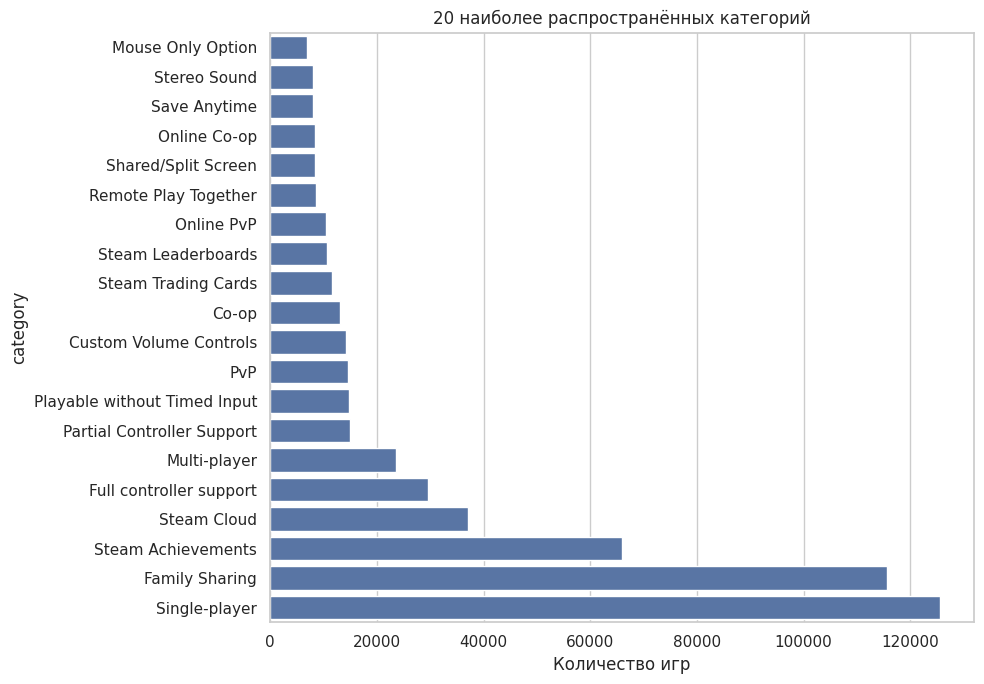

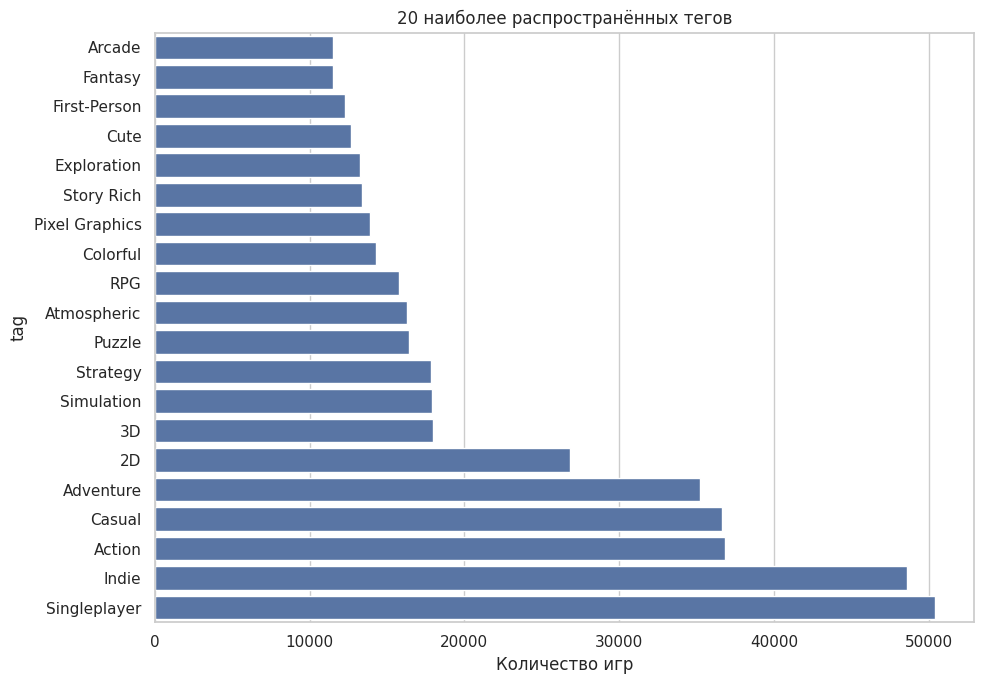

In [24]:
def show_top_multilabel(dataframe, column_name, title, filename):
    pdf = dataframe.limit(20).toPandas().sort_values("count")

    plt.figure(figsize=(10, 7))
    sns.barplot(data=pdf, x="count", y=column_name)
    plt.xlabel("Количество игр")
    plt.ylabel(column_name)
    plt.title(title)
    plt.tight_layout()
    plt.savefig(PLOTS_DIR / filename, dpi=150, bbox_inches="tight")
    plt.show()


show_top_multilabel(genres_df, "genre", "20 наиболее распространённых жанров", "08_top_genres.png")
show_top_multilabel(categories_df, "category", "20 наиболее распространённых категорий", "09_top_categories.png")
show_top_multilabel(tags_df, "tag", "20 наиболее распространённых тегов", "10_top_tags.png")


## 17. Распределение количества жанров, категорий и тегов на игру

> Всплеск на 20 у `tags_count` — это ограничение датасета: в исходном поле `tags` сохраняется не более 20 значений на игру.

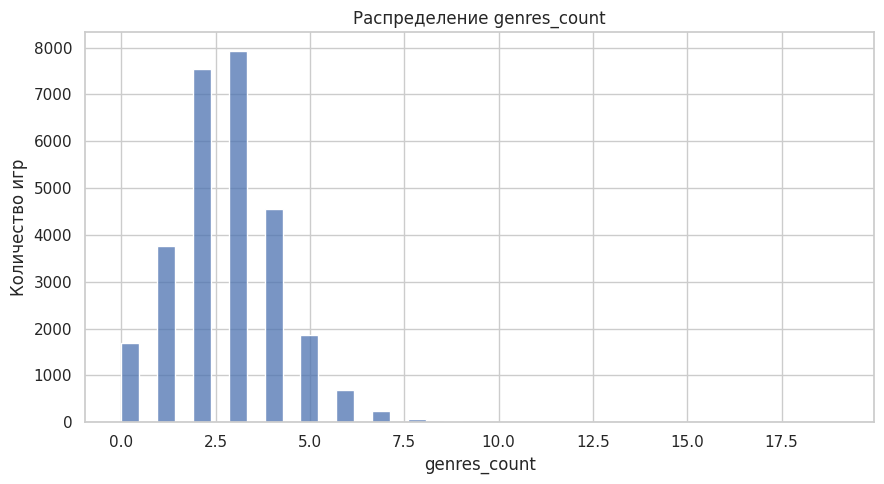

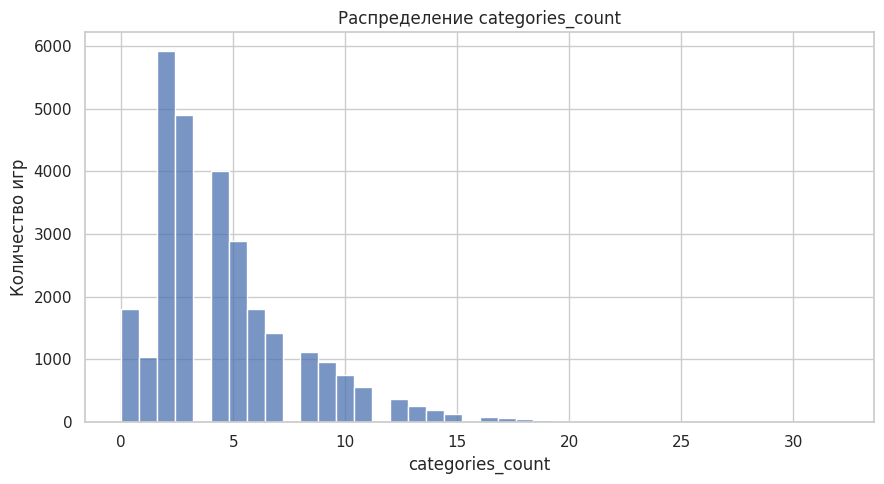

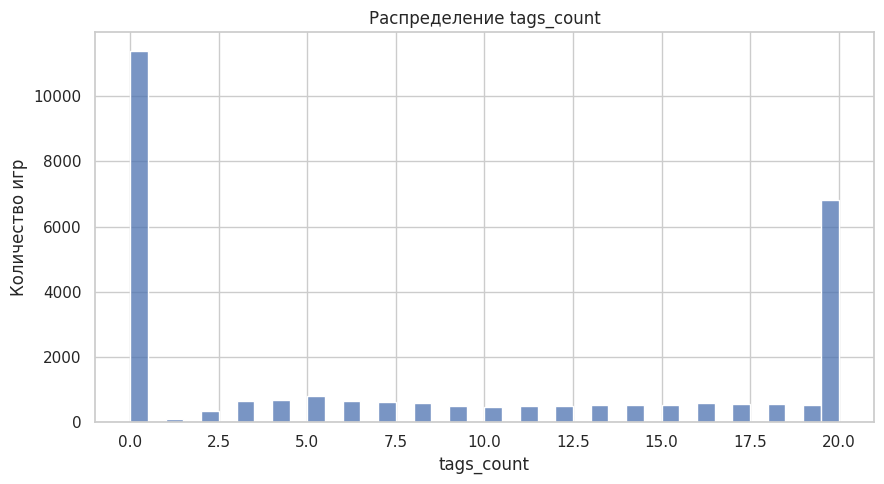

In [25]:
for column_name in ["genres_count", "categories_count", "tags_count"]:
    plot_raw_distribution(df_clean, column_name, PLOTS_DIR)


## 18. Показатели популярности

В качестве показателей популярности используются оценочное количество владельцев, число отзывов, рекомендации и пиковое количество одновременных пользователей. Из-за сильной асимметрии медиана здесь информативнее среднего.

In [26]:
popularity_columns = [
    "estimated_owners_avg",
    "reviews_total",
    "recommendations",
    "peak_ccu",
]

df_clean.select(*popularity_columns).summary(
    "count", "min", "25%", "50%", "mean", "75%", "max"
).show(truncate=False)


+-------+--------------------+------------------+---------------+-----------------+
|summary|estimated_owners_avg|reviews_total     |recommendations|peak_ccu         |
+-------+--------------------+------------------+---------------+-----------------+
|count  |141148              |141148            |106257         |141148           |
|min    |0.0                 |0                 |0              |0                |
|25%    |10000.0             |0                 |0              |0                |
|50%    |10000.0             |3                 |0              |0                |
|mean   |75875.57032334854   |1055.1682843540113|1162.9214922311|47.48437809958342|
|75%    |10000.0             |35                |0              |0                |
|max    |1.5E8               |8815087           |5179195        |1013936          |
+-------+--------------------+------------------+---------------+-----------------+



## 19. Популярность в зависимости от жанра

Для жанров считаем не только медианы, но и более устойчивые агрегаты:

- `games` — сколько игр в жанре;
- `mean_owners` — среднее число владельцев;
- `median_reviews_positive` — медиана отзывов **только среди игр с отзывами** (>0);
- `median_positive_ratio` — медиана доли положительных отзывов;
- `p90_peak_ccu` — 90-й перцентиль пикового онлайна.

Сортировка — по `median_reviews_positive`.

In [27]:
genre_popularity_df = (
    df_clean
    .select(
        explode("genres").alias("genre"),
        "estimated_owners_avg",
        "reviews_total",
        "positive_ratio",
        "peak_ccu",
    )
    .filter(col("genre").isNotNull())
    .groupBy("genre")
    .agg(
        count("*").alias("games"),
        avg("estimated_owners_avg").alias("mean_owners"),
        percentile_approx(
            when(col("reviews_total") > 0, col("reviews_total")),
            0.5, 10000
        ).alias("median_reviews_positive"),
        percentile_approx(
            col("positive_ratio"),
            0.5, 10000
        ).alias("median_positive_ratio"),
        percentile_approx(
            col("peak_ccu"),
            0.9, 10000
        ).alias("p90_peak_ccu"),
    )
    .filter(col("games") >= 100)
    .orderBy(desc("median_reviews_positive"))
)

genre_popularity_df.show(20, truncate=False)


+---------------------+-----+------------------+-----------------------+---------------------+------------+
|genre                |games|mean_owners       |median_reviews_positive|median_positive_ratio|p90_peak_ccu|
+---------------------+-----+------------------+-----------------------+---------------------+------------+
|Massively Multiplayer|2882 |429746.7036780014 |73                     |0.6666666666666666   |18          |
|Free To Play         |14494|159401.13150269075|69                     |0.7872340425531915   |1           |
|Web Publishing       |112  |75401.78571428571 |65                     |0.7636986301369864   |89          |
|RPG                  |24288|116255.14657444005|36                     |0.8                  |4           |
|Simulation           |28901|72923.7742638663  |33                     |0.7692307692307693   |3           |
|Adventure            |51184|88619.29509221631 |27                     |0.8132530120481928   |1           |
|Strategy             |26773

## 20. Корреляционный анализ

Из-за выбросов и нулевой инфляции Pearson на сырых данных даёт заниженные оценки. Поэтому используется **ранговая корреляция Спирмена**, устойчивая к выбросам и монотонным нелинейностям. `app_id` в матрицу не включается.

Корреляция описывает статистическую связь и **не означает причинно-следственную зависимость**.

In [28]:
correlation_columns = [
    "price",
    "estimated_owners_avg",
    "positive",
    "negative",
    "reviews_total",
    "positive_ratio",
    "recommendations",
    "peak_ccu",
    "metacritic_score",
    "average_playtime_forever",
    "median_playtime_forever",
    "achievements",
    "dlc_count",
    "supported_languages_count",
    "full_audio_languages_count",
    "genres_count",
    "categories_count",
    "tags_count",
    "platform_count",
]

correlation_pdf = (
    df_clean
    .select(*correlation_columns)
    .sample(False, 0.2, seed=42)
    .toPandas()
)

corr_spearman = correlation_pdf.corr(method="spearman", numeric_only=True)
corr_spearman.to_csv(RESULTS_DIR / "correlation_spearman.csv")

display(corr_spearman.round(3))


,price,estimated_owners_avg,positive,negative,reviews_total,positive_ratio,recommendations,peak_ccu,metacritic_score,average_playtime_forever,median_playtime_forever,achievements,dlc_count,supported_languages_count,full_audio_languages_count,genres_count,categories_count,tags_count,platform_count
price,1.000,0.371,0.286,0.262,0.290,0.025,0.427,0.281,0.265,0.262,0.262,0.327,0.181,0.179,0.125,0.055,0.357,0.273,0.106
estimated_owners_avg,0.371,1.000,0.659,0.630,0.670,-0.040,0.536,0.437,0.294,0.263,0.262,0.327,0.221,0.111,0.145,0.144,0.305,0.560,0.138
positive,0.286,0.659,1.000,0.877,0.989,0.071,0.561,0.512,0.403,0.320,0.320,0.298,0.233,0.193,0.190,0.092,0.195,0.797,0.150
negative,0.262,0.630,0.877,1.000,0.916,-0.451,0.582,0.495,0.199,0.316,0.316,0.261,0.223,0.196,0.196,0.100,0.171,0.674,0.122
reviews_total,0.290,0.670,0.989,0.916,1.000,-0.067,0.556,0.506,0.369,0.315,0.315,0.284,0.226,0.189,0.196,0.098,0.187,0.811,0.144
positive_ratio,0.025,-0.040,0.071,-0.451,-0.067,1.000,-0.037,0.064,0.549,0.042,0.042,0.056,0.045,-0.005,-0.062,-0.066,0.061,0.162,0.078
recommendations,0.427,0.536,0.561,0.582,0.556,-0.037,1.000,0.613,0.400,0.517,0.517,0.436,0.373,0.265,0.140,0.044,0.363,0.265,0.150
peak_ccu,0.281,0.437,0.512,0.495,0.506,0.064,0.613,1.000,0.438,0.460,0.459,0.260,0.259,0.245,0.122,0.027,0.177,0.345,0.105
metacritic_score,0.265,0.294,0.403,0.199,0.369,0.549,0.400,0.438,1.000,0.232,0.230,0.154,0.166,0.205,0.050,-0.046,0.163,0.310,0.053
average_playtime_forever,0.262,0.263,0.320,0.316,0.315,0.042,0.517,0.460,0.232,1.000,1.000,0.190,0.226,0.236,0.118,0.040,0.142,0.227,0.028


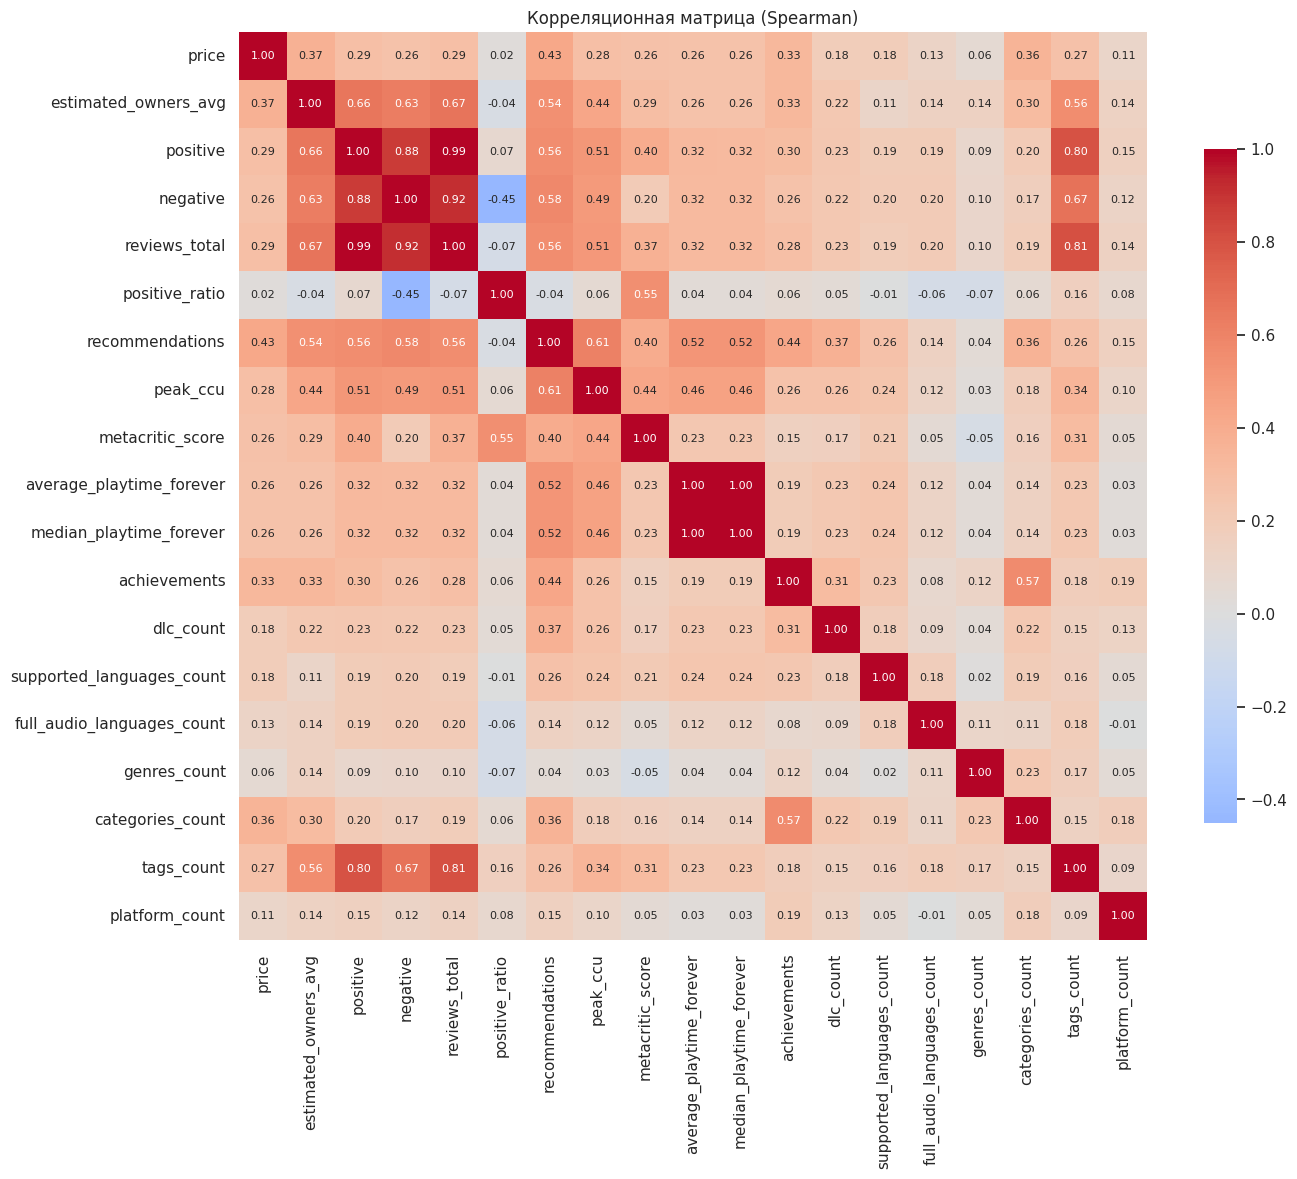

In [29]:
plt.figure(figsize=(14, 12))
sns.heatmap(
    corr_spearman,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    square=True,
    cbar_kws={"shrink": 0.7},
    annot_kws={"size": 8},
)
plt.title("Корреляционная матрица (Spearman)")
plt.tight_layout()
plt.savefig(PLOTS_DIR / "11_correlation_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()


## 21. Выводы по разведочному анализу

По результатам разведочного анализа подготовленной Iceberg-таблицы `steam_games` можно сформулировать следующие наблюдения.

**Качество данных.**
- `app_id` уникален и не содержит пропусков — набор пригоден для анализа на уровне игр.
- Основные пропуски сосредоточены в признаках `metacritic_score` (29.9%), `recommendations` (24.7%), `achievements` (13.0%) и `supported_languages_count` (5.9%).
- После перевода `metacritic_score = 0` в `NULL` доля пропусков по этому признаку стала ещё больше — это корректно, так как `0` в исходных данных означал отсутствие оценки.
- Проверка логических ограничений не выявила отрицательных цен, отзывов, времени игры и выхода `metacritic_score` за диапазон [0; 100].
- В массивах `categories` встречались дубликаты значений (порядка 1.2% игр), они устранены через `array_distinct`.

**Распределения.**
- Почти все количественные признаки (`reviews_total`, `recommendations`, `peak_ccu`, время игры, число владельцев) имеют сильную правостороннюю скошенность и высокую долю нулей. Сырые гистограммы неинформативны, поэтому анализ ведётся в `log1p`-масштабе по положительным значениям.
- `estimated_owners_avg`, `reviews_total` и `recommendations` концентрируются в узком диапазоне нижних значений, но имеют длинный хвост до десятков миллионов.
- Цена платных игр имеет модальное значение около 5–10 у.е.; присутствует редкое аномальное значение 107500, отражающее реальные дорогие издания Steam.
- Признак `tags_count` имеет всплеск на 20 — это ограничение исходного поля, а не артефакт обработки.

**Категориальные признаки.**
- Наиболее распространённые жанры: Indie, Casual, Action, Adventure, Simulation.
- Наиболее распространённые категории: Single-player, Family Sharing, Steam Achievements, Steam Cloud.
- Наиболее частые теги: Singleplayer, Indie, Action, Casual, Adventure, 2D, 3D.

**Корреляции (Spearman).**
- Сильная положительная связь между `positive`, `reviews_total`, `recommendations` и `peak_ccu`: игры с большим числом отзывов обычно имеют и большую аудиторию.
- `metacritic_score` умеренно связан с `positive_ratio` и `reviews_total`: критическая оценка согласуется с пользовательской.
- `price` слабо коррелирует с популярностью: цена сама по себе не объясняет успех игры.
- `categories_count` и `tags_count` умеренно связаны с популярностью — более «проработанные» игры с большим числом категорий и тегов чаще имеют большую аудиторию.

**Использование в ML (Лаба 2).**
- В качестве целевых переменных для Лабораторной работы №2 выбраны `price` (регрессия) и `positive_ratio` (классификация).
- Для регрессии `price` целесообразно либо ограничиться платными играми, либо использовать `log1p(price)` как таргет, поскольку распределение цены сильно скошено.
- Для бинарной классификации `positive_ratio` естественным порогом является 0.8 — граница между «очень положительными» и остальными играми.
- Признаки `estimated_owners_avg`, `reviews_total`, `recommendations` и `peak_ccu` необходимо логарифмировать, а перед обучением — проверить на утечку (признак `positive` напрямую входит в `positive_ratio` и использовать его нельзя).
